### **Time Series**

In [1]:
import plotly.io as pio
pio.renderers.default = "iframe"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from prophet import Prophet
from xgboost import XGBRegressor
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.holtwinters import ExponentialSmoothing
#from tensorflow.keras.layers import Dense, LSTM
#from tensorflow.keras.models import Sequential
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

Time Series შეიძლება ჰქონდეს შემდეგი კომპონენტები:

| კომპონენტი                          | აღწერა                                                                                 |
| ----------------------------------- | -------------------------------------------------------------------------------------- |
| ტრენდი (T)                   | გრძელვადიანი ცვლილება საშუალო მნიშვნელობაში (მაგ. გაყიდვების ზრდა წლების განმავლობაში) |
| სეზონურობა (S)               | პერიოდული ციკლები, რომლებიც რეგულარულად მეორდება (მაგ. ზაფხულში ნაყინის გაყიდვები)     |
| შემთხვევითი რყევები (R)      | ისეთი ცვლილებები, რომლებსაც რეგულარობა არ აქვთ – "ხმაური"                              |
| ციკლურობა| ხანგრძლივი ციკლები, რომლებიც წლების განმავლობაში მეორდება (მაგ. ეკონომიკური კრიზისები) |


Additive და Multiplicative მოდელები:

* Additive:
  $y(t) = T(t) + S(t) + R(t)$
  → კომპონენტები დამოუკიდებელია

* Multiplicative:
  $y(t) = T(t) \cdot S(t) \cdot R(t)$
  → სეზონური ეფექტი იზრდება ტრენდის შესაბამისად

### Airline Passengers Dataset

In [4]:
df_passengers = pd.read_csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv")
df_passengers.columns = ["Timestamp", "Passengers"]
df_passengers.set_index("Timestamp", inplace=True)
df_passengers.index = pd.to_datetime(df_passengers.index)
df_passengers["Month"] = df_passengers.index.month_name()
df_passengers["Year"] = df_passengers.index.year
df_passengers.head()

,Passengers,Month,Year
Timestamp,,,
1949-01-01,112,January,1949
1949-02-01,118,February,1949
1949-03-01,132,March,1949
1949-04-01,129,April,1949
1949-05-01,121,May,1949


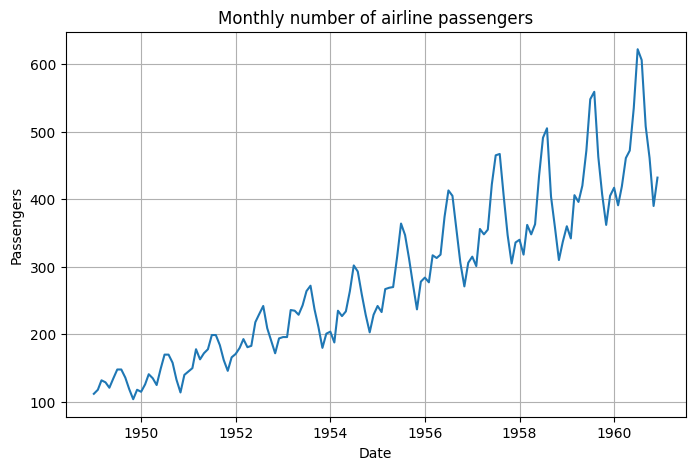

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(df_passengers["Passengers"])
plt.title("Monthly number of airline passengers")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.grid(True)
plt.show()

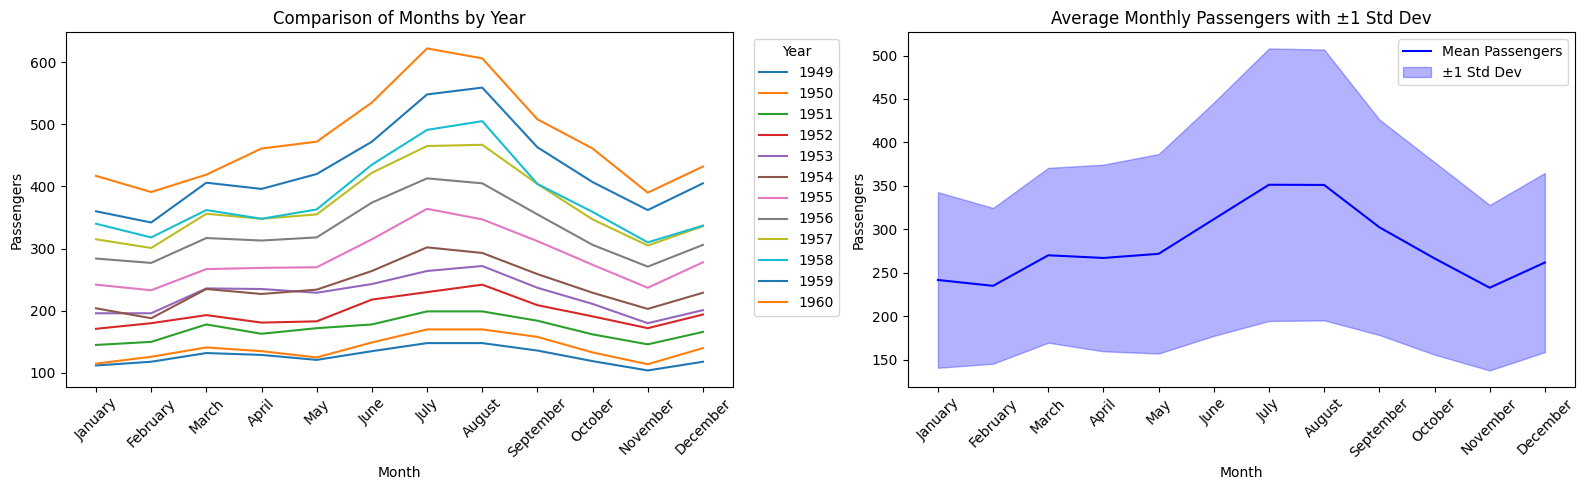

In [6]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

monthly_mean = df_passengers.groupby("Month")["Passengers"].mean().reindex(month_order)
monthly_std = df_passengers.groupby("Month")["Passengers"].std().reindex(month_order)
months = monthly_mean.index

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(
    data=df_passengers,
    x="Month",
    y="Passengers",
    hue="Year",
    palette="tab10",
    ax=axes[0]
)
axes[0].set_title("Comparison of Months by Year")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Passengers")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="Year", bbox_to_anchor=(1.02, 1), loc="upper left")

axes[1].plot(months, monthly_mean, label="Mean Passengers", color="blue")
axes[1].fill_between(
    months,
    monthly_mean - monthly_std,
    monthly_mean + monthly_std,
    alpha=0.3,
    label="±1 Std Dev",
    color="blue"
)
axes[1].set_title("Average Monthly Passengers with ±1 Std Dev")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Passengers")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

Seasonal decompose ყოფს time series სამ კომპონენტად, რათა უკეთ გავიგოთ მისი სტრუქტურა და უკეთესი პროგნოზი შევძლოთ.

---

Time series $Y_t$ შეიძლება გამოიხატოს ორ მოდელად:

1. Additive Model

$$
Y_t = T_t + S_t + R_t
$$

2. Multiplicative Model

$$
Y_t = T_t \times S_t \times R_t
$$

სადაც:

* $Y_t$: მნიშვნელობა დროის მომენტში t
* $T_t$: ტრენდი
* $S_t$: სეზონური კომპონენტი
* $R_t$: რეზიდუალური კომპონენტი

---

1. ტრენდი (Tₜ)

* აღწერს სერიის გრძელვადიან მიმართულებას
* ხორციელდება rolling mean-ით

2. სეზონურობა (Sₜ)

* განმეორებადი შაბლონი, რომელიც ფიქსირებულ პერიოდში ხდება
* ასახავს სეზონურ ეფექტებს, როგორიცაა წელიწადის დროები ან დღესასწაულები

3. რეზიდუალური/შესაბამისი (Rₜ)

* რაც დარჩა ტრენდისა და სეზონურობის ამოღების შემდეგ
* ითვლება შემთხვევით ხმაურად, რომელსაც არ უნდა ჰქონდეს მკაფიო სტრუქტურა

---

| მახასიათებელი     | ადიტიური მოდელი              | მულტიპლიკატიური მოდელი               |
| ----------------- | ---------------------------- | ------------------------------------ |
| სეზონური მერყეობა | მუდმივი (ფიქსირებული სიდიდე) | დამოკიდებულია ტრენდის დონეზე         |
| გამოიყენება როცა     | დისპერსია სტაბილურია         | დისპერსია იზრდება დროის განმავლობაში |
| გრაფიკზე ჩანს     | ჰორიზონტალური სეზონურობა     | ზრდადი/კლებადი სეზონურობა           |

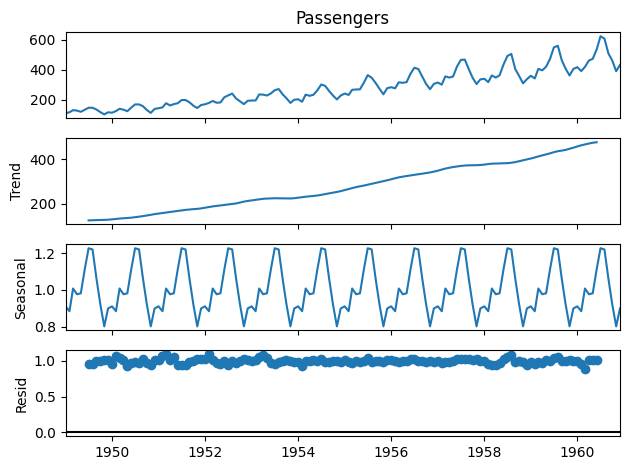

In [7]:
# დეკომპოზიცია
result = seasonal_decompose(df_passengers["Passengers"], model="multiplicative", period=12)
result.plot()
plt.show()

In [8]:
df_passengers["Passengers"].rolling(window=12, center=True).mean()[:13]

Timestamp
1949-01-01           NaN
1949-02-01           NaN
1949-03-01           NaN
1949-04-01           NaN
1949-05-01           NaN
1949-06-01           NaN
1949-07-01    126.666667
1949-08-01    126.916667
1949-09-01    127.583333
1949-10-01    128.333333
1949-11-01    128.833333
1949-12-01    129.166667
1950-01-01    130.333333
Name: Passengers, dtype: float64

In [9]:
# seasonal_decompose-ის კომპონენტები
df_passengers["Trend"] = result.trend
df_passengers["Seasonal"] = result.seasonal
df_passengers["Resid"] = result.resid

df_pass = df_passengers.dropna().copy()
df_pass.head()

,Passengers,Month,Year,Trend,Seasonal,Resid
Timestamp,,,,,,
1949-07-01,148,July,1949,126.791667,1.226556,0.951664
1949-08-01,148,August,1949,127.250000,1.219911,0.953401
1949-09-01,136,September,1949,127.958333,1.060492,1.002220
1949-10-01,119,October,1949,128.583333,0.921757,1.004028
1949-11-01,104,November,1949,129.000000,0.801178,1.006270


In [10]:
X_train = np.arange(len(df_pass)).reshape(-1, 1)
y_train = df_pass["Trend"]

In [11]:
# გავწვრთნათ linear regression სამომავლო ტრენდის განსასაზღვრად
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [12]:
last_date = df_passengers.index[-1]
future_index = pd.date_range(start=last_date + pd.DateOffset(months=1), periods=12, freq="MS")

X_test = np.arange(len(df_passengers), len(df_passengers) + 12).reshape(-1, 1)
y_pred = model.predict(X_test)

* Multiplicative:
  $y(t) = T(t) \cdot S(t) \cdot R(t)$

| კომპონენტი      | პროგნოზისას | მიზეზი                                                |
| --------------- | --------------------- | ----------------------------------------------------- |
| ტრენდი     | გამოყენება                | გრძელვადიანი ტენდენცია                                |
| სეზონურობა  | გამოყენება                | განმეორებადი პატერნები                                |
| რეზიდუალები| არ გამოყენება                 | შემთხვევითი შეცდომები, პროგნოზირებას არ ექვემდებარება |


In [13]:
df_future = pd.DataFrame({"Trend": y_pred}, index=future_index)
df_future["Seasonal"] = df_passengers["Seasonal"][-12:].values
# გადავამრავლოთ კომპონენტები, რადგანაც გამოვიყენეთ multiplicative model
df_future["Passengers"] = df_future["Trend"] * df_future["Seasonal"] 
df_future

,Trend,Seasonal,Passengers
1961-01-01,487.355878,0.910230,443.606120
1961-02-01,490.022816,0.883625,432.996568
1961-03-01,492.689753,1.007366,496.319048
1961-04-01,495.356691,0.975906,483.421573
1961-05-01,498.023629,0.981378,488.749447
1961-06-01,500.690567,1.112776,557.156359
1961-07-01,503.357504,1.226556,617.395937
1961-08-01,506.024442,1.219911,617.304768
1961-09-01,508.691380,1.060492,539.463105
1961-10-01,511.358318,0.921757,471.348232


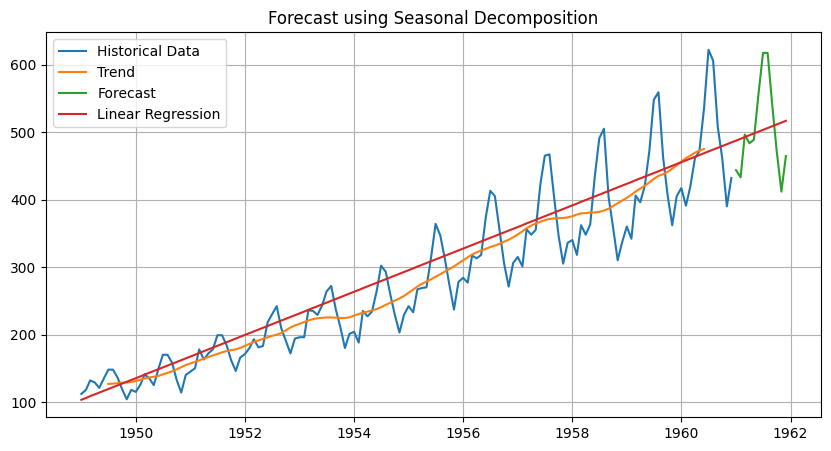

In [14]:
indices = np.arange(len(df_passengers) + 12).reshape(-1, 1)
time_range = pd.date_range(start=df_passengers.index[0], end=df_future.index[-1], freq="MS")
reg_fit = model.predict(indices)
df_reg = pd.DataFrame({"Trend": reg_fit}, index=time_range)

plt.figure(figsize=(10, 5))
plt.plot(df_passengers["Passengers"], label="Historical Data")
plt.plot(df_passengers["Trend"], label="Trend")
plt.plot(df_future["Passengers"], label="Forecast")
plt.plot(df_reg["Trend"], label="Linear Regression")
plt.title("Forecast using Seasonal Decomposition")
plt.legend()
plt.grid()
plt.show()

Seasonal Decompositon უფრო გამოიყენება მონაცემების ანალიზის მიზნით (Exploration), სასარგებლოა დროის სერიის სტრუქტურის შესასწავლად – ანუ სეზონურობის, ტრენდისა და რყევის კომპონენტების გამოსაყოფად. რაც შეეხება პროგნოზს, გვაქვს უფრო ძლიერი მოდელები, როგორიცაა ARIMA, SARIMA.

----

### Fundamentals of Time Series Analysis

აუტოკორელაცია არის ერთ-ერთი მთავარი ცნება დროის სერიების ანალიზში.
ის გვიჩვენებს რამდენად ძლიერად არის მიმდინარე მნიშვნელობები დაკავშირებული წინა მნიშვნელობებთან. ვთქვათ გვაქვს ტემპერატურის მონაცემები:
| დღე       | ტემპერატურა |
| --------- | ----------- |
| ორშაბათი  | 15 °C       |
| სამშაბათი | 17 °C       |
| ოთხშაბათი | 18 °C       |
| ხუთშაბათი | 16 °C       |

Lag (time delay)

Lag = 1 (პირველი რიგის აუტოკორრელაცია $\text{Corr}(X_t, X_{t-1})$) ნიშნავს რომ ვადარებთ სამშაბათს ორშაბათს, ოთხშაბათს სამშაბათს და ა.შ.

Lag = 2 (მეორე რიგის აუტოკორრელაცია $\text{Corr}(X_t, X_{t-2})$) ნიშნავს რომ ვადარებთ ოთხშაბათს ორშაბათს, ხუთშაბათს სამშაბათს და ასე შემდეგ.

თუ აუტოკორელაცია დიდია Lag = 1-ზე ეს ნიშნავს, რომ დროის სერია ნელა იცვლება და წინა მნიშვნელობები გავლენას ახდენს შემდეგ მნიშვნელობებზე.

სეზონური ავტოკორელაცია ($\text{Corr}(X_t, X_{t-s})-\text{სადაც } s \text{ არის სეზონური პერიოდი}$) ნიშნავს, რომ დროის სერიაში არსებობს პერიოდული გამეორებადობა და მნიშვნელობები ერთმანეთს ემთხვევა ფიქსირებულ ინტერვალებზე:
* კვირაში ერთხელ გამეორებადი ტენდენცია: Lag = 7 (დღეებზე)
* წლიური სეზონურობა: Lag = 12 (თვეზე დაფუძნებული სერიებისთვის)

---
დროითი სერია სტაციონარულია, თუ მისი სტატისტიკური თვისებები (საშუალო, დისპერსია) დროის გასვლის მიუხედავად არ იცვლება.

როგორ ვამოწმებთ სტაციონარობას?

* ვიზუალურად: არ უნდა ჩანდეს ტრენდი ან ცვალებადი მერყეობა
* სტატისტიკურად: ADF ტესტი (Augmented Dickey-Fuller)

დროის სერია, რომელსაც აქვს მნიშვნელოვანი ავტოკორელაცია, ხშირად არ არის სტატიონარული.

In [15]:
# თეთრი ხმაურის გენერაცია
np.random.seed(0)
n = 1000
white_noise = np.random.normal(loc=0.0, scale=1.0, size=n)

# დროის ფანჯარა
window_size = 100
windows = [white_noise[i:i+window_size] for i in range(0, n, window_size)]

# საშუალო და დისპერსია თითოეულ ფანჯარაში
means = [np.mean(w) for w in windows]
variances = [np.var(w) for w in windows]

# ავტოკორელაციის გამოთვლა
lags = 40
acf_values = acf(white_noise, nlags=lags)

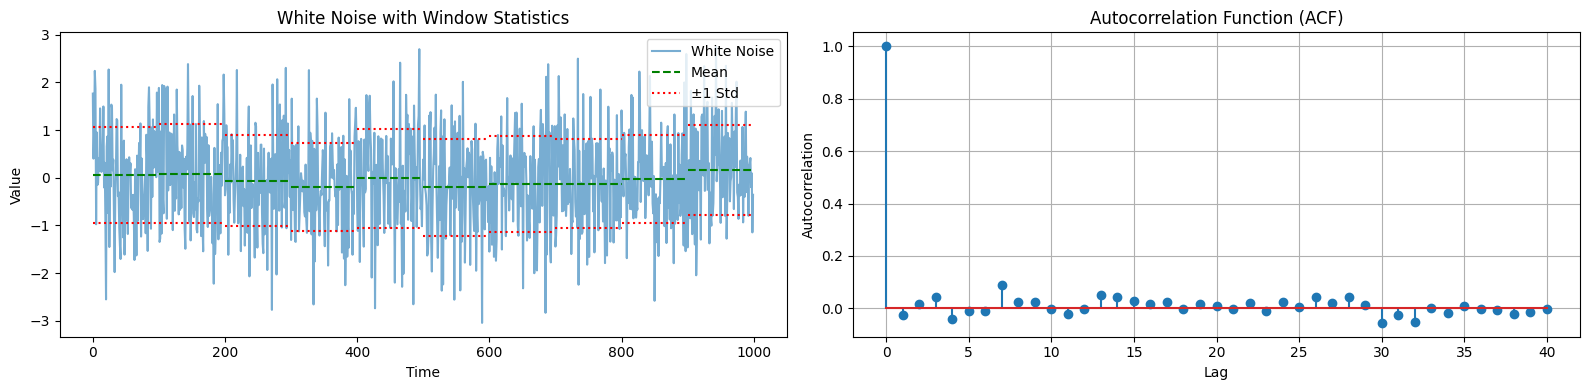

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(16, 4))
axs[0].plot(white_noise, label="White Noise", alpha=0.6)
for i, (mean, var) in enumerate(zip(means, variances)):
    start = i * window_size
    end = start + window_size
    axs[0].hlines(mean, start, end, colors="green", linestyles="dashed", label="Mean" if i == 0 else "")
    axs[0].hlines([mean + np.sqrt(var), mean - np.sqrt(var)], start, end,
                  colors="red", linestyles="dotted", label="±1 Std" if i == 0 else "")
axs[0].set_title("White Noise with Window Statistics")
axs[0].set_xlabel("Time")
axs[0].set_ylabel("Value")
axs[0].legend(loc="upper right")

axs[1].stem(range(lags+1), acf_values)
axs[1].set_title("Autocorrelation Function (ACF)")
axs[1].set_xlabel("Lag")
axs[1].set_ylabel("Autocorrelation")
axs[1].grid()

plt.tight_layout()
plt.show()

გრაფიკიდან როგორც ვხედავთ, სტატისტიკური თვისებები არ იცვლება დროში → სტაციონარულია.
* Mean თითქმის უცვლელია (ხშირად 0)
* ვარიაცია მუდმივი რჩება
* ავტოკორელაცია მაღალია მხოლოდ Lag = 0-ზე, ხოლო დანარჩენ შემთხვევებში თითქმის 0 → არ აქვს დროითი დამოკიდებულება

ACF (Autocorrelation Function) ზომავს სრულ (პირდაპირ და არაპირდაპირ) კავშირს დროით სერიასა და მის წაჩოჩებულ ვერსიებს შორის.

ACF lag = 2-ზე გვიჩვენებს, როგორ არის xₜ დაკავშირებული xₜ₋₂-თან, xₜ₋₁-ის გავლენის ჩათვლით.

PACF (Partial Autocorrelation Function) ზომავს მხოლოდ პირდაპირ კავშირს xₜ და xₜ₋ₖ შორის.

PACF lag = 2-ზე გვიჩვენებს, რამდენად არის xₜ პირდაპირ დაკავშირებული xₜ₋₂-თან, არ ითვალისწინებს xₜ₋₁-ს გავლენას.

| ფუნქცია  | ზომავს                   |
| -------- | ------------------------------- | 
| ACF | პირდაპირ და არაპირდაპირ კავშირს | 
| PACF | მხოლოდ პირდაპირ კავშირს         |


---
მოდელები:
* ARIMA - ავტორეგრესიული მოდელი სტაციონარულ სერიებზე   
* SARIMA - ARIMA სეზონური კომპონენტით    
* Prophet - Facebook-ის მოდელი, ადვილი გამოსაყენებლად  
* LSTM - ნეირონული ქსელები რთული დროითი პატერნებისთვის 

---

1. ანალიზი: მონაცემების ვიზუალიზაცია და კომპონენტების გამოვლენა
2. მოდელირება: მათემატიკური მოდელის მორგება (მაგ. ARIMA, Prophet)
3. პროგნოზი: მომავლის მნიშვნელობების წინასწარ განსაზღვრა

---

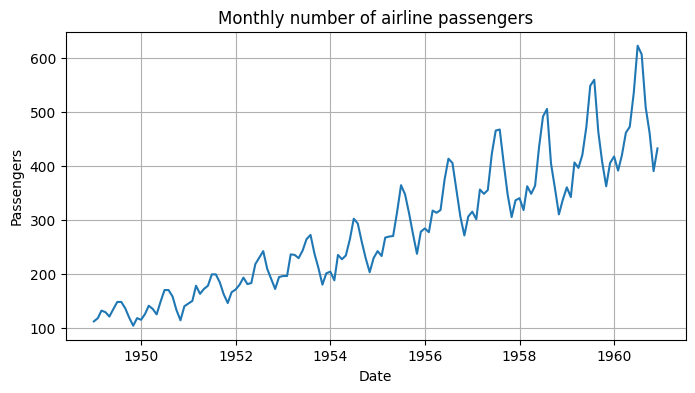

In [17]:
plt.figure(figsize=(8, 4))
plt.plot(df_passengers["Passengers"])
plt.title("Monthly number of airline passengers")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.grid(True)
plt.show()

გრაფიკიდან როგორც ვხედავთ, სტატისტიკური თვისებები დროში იცვლება:
* Mean იცვლება
* ვარიაცია იცვლება

ADF ტესტის (Augmented Dickey–Fuller) მნიშვნელობა

ADF ტესტი გამოიყენება იმის შესამოწმებლად, არის თუ არა დროითი სერია სტაციონარული, ანუ დროთა განმავლობაში მისი სტატისტიკური თვისებები (საშუალო, დისპერსია) არ იცვლება.

| ჰიპოთეზა                       | ინტერპრეტაცია                                                                                     |
| ------------------------------ | ------------------------------------------------------------------------------------------------- |
| H₀ (ნულოვანი ჰიპოთეზა)    | სერია არასტაციონარულია (შეიძლება ჰქონდეს ტრენდი ან დრიფტი) |
| H₁ (ალტერნატიული ჰიპოთეზა) | სერია სტაციონარულია   (საშუალო, დისპერსია არ იცვლება)     |

p-value-ის ინტერპრეტაცია:

* p-value ≥ 0.05
  → ვერ ვუარყოფთ H₀-ს
  → სერია არასტაციონარულია

* p-value < 0.05
  → ვუარყოფთ H₀-ს
  → სერია სტაციონარულია

In [18]:
# ვამოწმებთ სტაციონარობას
# -3.43 (1% level), -2.86 (5% level), and -2.57 (10% level)
result = adfuller(df_passengers["Passengers"])
print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: 0.815368879206053
p-value: 0.9918802434376411


| მნიშვნელობა        | ახსნა                                                          |
| ------------------ | -------------------------------------------------------------- |
| ADF Statistic  | რაც უფრო დაბალია, მით უფრო სავარაუდოა სტაციონარობა             |
| p-value = 0.99 | ძალიან მაღალია, ნიშნავს რომ სერია არ არის სტაციონარული |

თუ სერია არ არის სტაციონარული → საჭიროა ტრენდისა და სეზონური კომპონენტების მოცილება (differencing, detrending).

დროის სერია $Y_t$ ხდება სტაციონარული მას შემდეგ, რაც მასზე ვახორციელებთ $d$-ჯერ დიფერენცირებას:

$$
Y_t" = Y_t - Y_{t-1} \quad (\text{თუ } d=1)
$$

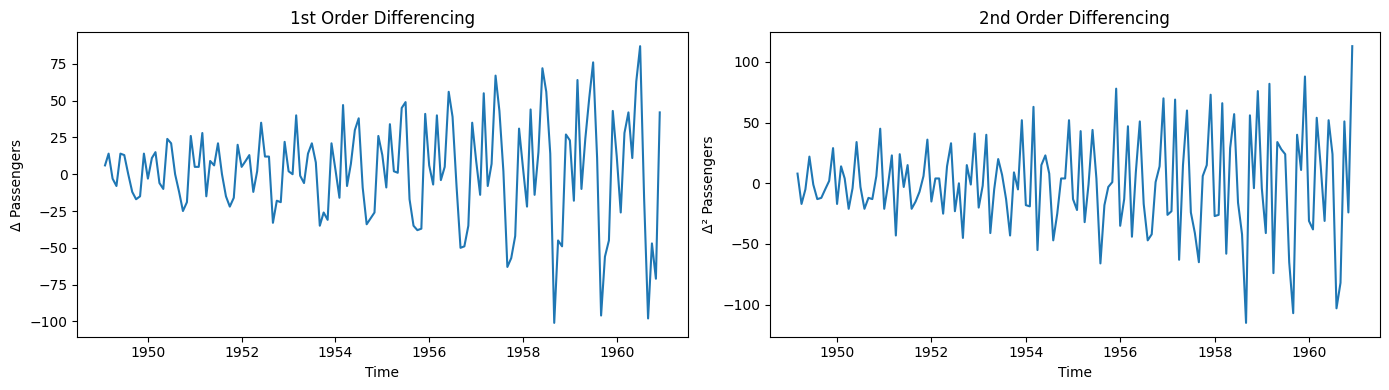

In [19]:
# ასე სერიას ვაქცევთ სტაციონარულად
df_diff = df_passengers["Passengers"].diff().dropna()

# მეორე დიფერენცირება
df_diff2 = df_diff.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(df_diff)
axes[0].set_title("1st Order Differencing")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Δ Passengers")

axes[1].plot(df_diff2)
axes[1].set_title("2nd Order Differencing")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Δ² Passengers")

plt.tight_layout()
plt.show()

In [20]:
result = adfuller(df_diff)
print("ADF:", result[0])
print("p-value:", result[1].round(10)) # თუ ახალი p-value იქნება < 0.05, სერია ახლა უკვე სტაციონარულია და შეგვიძლია გამოვიყენოთ ARIMA.

ADF: -2.8292668241700034
p-value: 0.0542132903


ეს p-value უკვე ბევრად დაბალია, მაგრამ მაინც 0.05-ზე ოდნავ ზემოთაა.

| მახასიათებელი                 | ACF (Autocorrelation Function)                                            | PACF (Partial Autocorrelation Function)                                  |
| ----------------------------- | ----------------------------------------------------------------------------- | ---------------------------------------------------------------------------- |
| რას ზომავს                    | სრულ კავშირს დროით სერიასა და მის წაჩოჩებულ ვერსიებს შორის                    | მხოლოდ პირდაპირ კავშირს დროით სერიასა და მის წაჩოჩებულ ვერსიებს შორის        |
| კავშირის ტიპი                 | პირდაპირი + არაპირდაპირი                                                  | მხოლოდ პირდაპირი                                                         |
| ACF / PACF $lag = 2$            | აჩვენებს კავშირს $x_t$ და $x_{t-2}$-ს შორის, $x_{t-1}$-ის გავლენის ჩათვლით | აჩვენებს კავშირს $x_t$ და $x_{t-2}$-ს შორის $x_{t-1}$-ის გავლენის გარეშე |


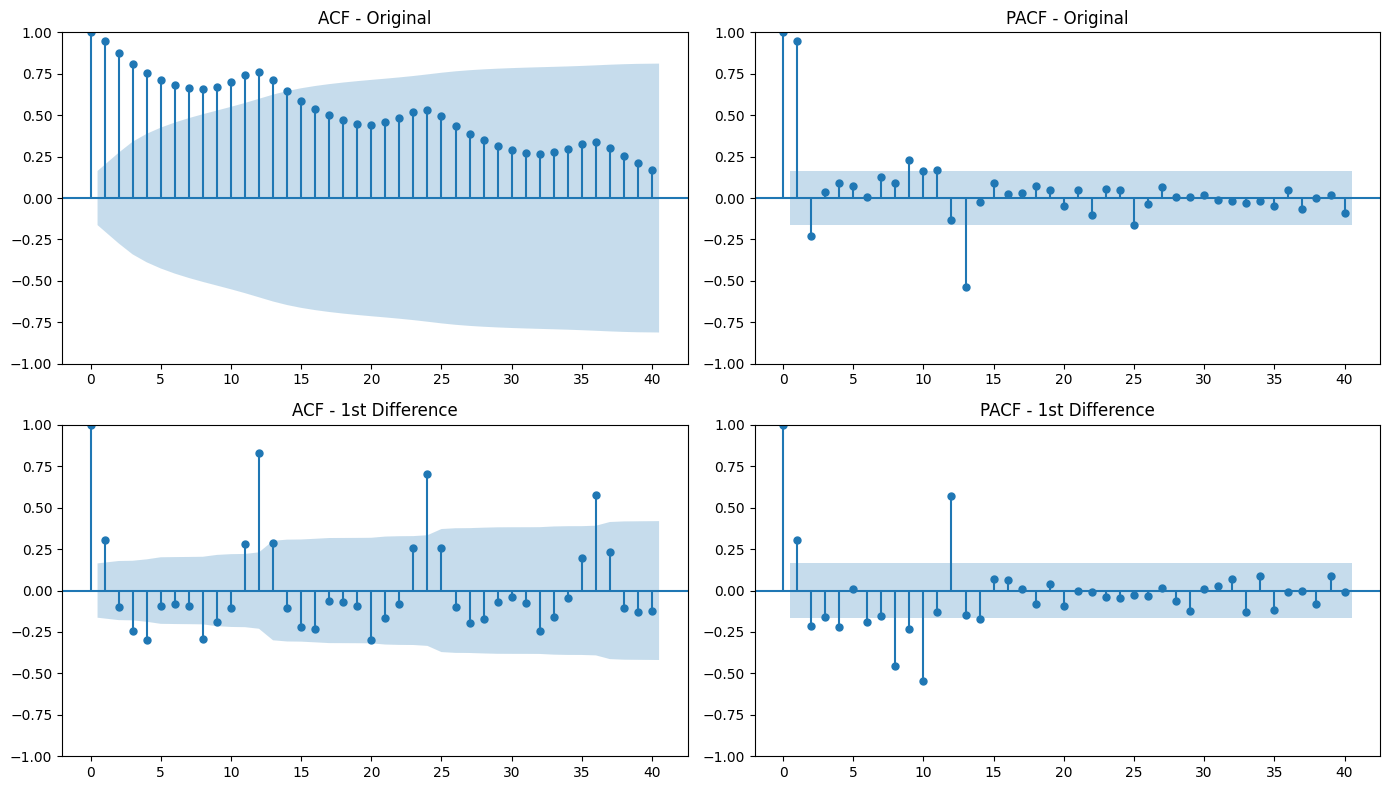

In [21]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8))

# ACF - Original:
# ავტოკორელაციის გრაფიკი თავდაპირველი (არადიფერენცირებული) დროის სერიისთვის.
# თუ მრავალი Lag მნიშვნელოვანია - ეს მიუთითებს, რომ სერია არ არის სტაციონარული.
plot_acf(df_passengers["Passengers"].dropna(), lags=40, ax=axes[0, 0])
axes[0, 0].set_title("ACF - Original")

# PACF - Original:
# ნაწილობრივი ავტოკორელაციის გრაფიკი თავდაპირველი დროის სერიისთვის.
# გამოიყენება AR (p) პარამეტრის დასადგენად, ანუ რამდენი წარსული მნიშვნელობა ახდენს გავლენას.
plot_pacf(df_passengers["Passengers"].dropna(), lags=40, ax=axes[0, 1], method="ywm")
axes[0, 1].set_title("PACF - Original")

# ACF - 1st Difference:
# დიფერენცირებული სერიის ავტოკორელაციის გრაფიკი.
# აქ სწრაფად კლებადი მნიშვნელობები მიუთითებს სტაციონარობაზე.
# გამოიყენება MA (q) პარამეტრის დასადგენად.
plot_acf(df_passengers["Passengers"].diff().dropna(), lags=40, ax=axes[1, 0])
axes[1, 0].set_title("ACF - 1st Difference")

# PACF - 1st Difference:
# დიფერენცირებული სერიის ნაწილობრივი ავტოკორელაციის გრაფიკი.
# კარგად ჩანს რამდენი წარსული მნიშვნელობა უნდა გავითვალისწინოთ (AR - p).
plot_pacf(df_passengers["Passengers"].diff().dropna(), lags=40, ax=axes[1, 1], method="ywm")
axes[1, 1].set_title("PACF - 1st Difference")

plt.tight_layout()
plt.show()

### ARIMA (AutoRegressive Integrated Moving Average)

ARIMA არის ერთ-ერთი ყველაზე პოპულარული მოდელი დროითი სერიების პროგნოზირებისთვის, განსაკუთრებით მაშინ, როცა:

* სერიას არ აქვს სეზონურობა
* გვსურს წარსულზე დაყრდნობით მომავლის პროგნოზი

ARIMA-ს აქვს 3 ძირითადი კომპონენტი:

| კომპონენტი | სიმბოლო | მნიშვნელობა                                                            |
| ---------- | ------- | ---------------------------------------------------------------------- |
| AR     | `p`     | ავტორეგრესია: წარსული მნიშვნელობების გამოყენება                        |
| I      | `d`     | ინტეგრაცია: რამდენჯერ უნდა დიფერენცირდეს სერია რომ გახდეს სტაციონარული |
| MA     | `q`     | მოძრავი საშუალო: წარსული შეცდომების გამოყენება                         |

---

1. AR(p) — ავტორეგრესიული ნაწილი

გამოიყენება წარსული მნიშვნელობები სერიის განსახილველად:

$$
y_t = c + \phi_1 y_{t-1} + \phi_2 y_{t-2} + \dots + \phi_p y_{t-p} + \varepsilon_t
$$

---

 2. I(d) — ინტეგრირებული ნაწილი

ეს ნიშნავს რამდენჯერ უნდა გავაკეთოთ დიფერენცირება, რომ სერია გახდეს სტაციონარული.

* `d = 1`: ვაკეთებთ `y(t) - y(t-1)`
* `d = 2`: ორჯერ დიფერენცირებულს ვიყენებთ

---

3. MA(q) — მოძრავი საშუალო ნაწილი

გამოიყენება წარსული შეცდომები პროგნოზირებისთვის:

$$
y_t = c + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \theta_2 \varepsilon_{t-2} + \dots + \theta_q \varepsilon_{t-q}
$$

---

როგორ ავარჩიოთ `p`, `d`, `q`?

* `d` შეგვიძლია ვნახოთ ADF ტესტით — რამდენჯერ გვჭირდება დიფერენცირება
* `p` და `q` შეიძლება აირჩეს `PACF` და `ACF` გრაფების გამოყენებით
* ან ავტომატურად ვიპოვოთ `auto_arima` ფუნქციით

---

* `ARIMA(1, 1, 1)` ნიშნავს:

  * 1 წარსული მნიშვნელობის გამოყენება (AR) 
  * 1-ჯერ დიფერენცირება (I)
  * 1 წარსული შეცდომის გამოყენება (MA)

$$
Y_t" = c + \phi_1 Y_{t-1}" + \theta_1 \varepsilon_{t-1} + \varepsilon_t
$$

ფორმულიდანაც ვხედავთ, $Y_t"$ დამოკიდებულია წინა მნიშვნელობაზე ($Y_{t-1}"$) და წინა შეცდომაზე ($\varepsilon_{t-1}$)
* $Y_{t-1}"$: წინა დიფერენცირებული მნიშვნელობა ($Y_{t-1}" = Y_{t-1} - Y_{t-2}$)
* $\varepsilon_{t-1}$: წინა პროგნოზის შეცდომა ($\varepsilon_{t-1} = Y_{t-1}" - \hat{Y}_{t-1}"$)
* $\varepsilon_t$: მიმდინარე შეცდომა (რომელიც შემთხვევითია)

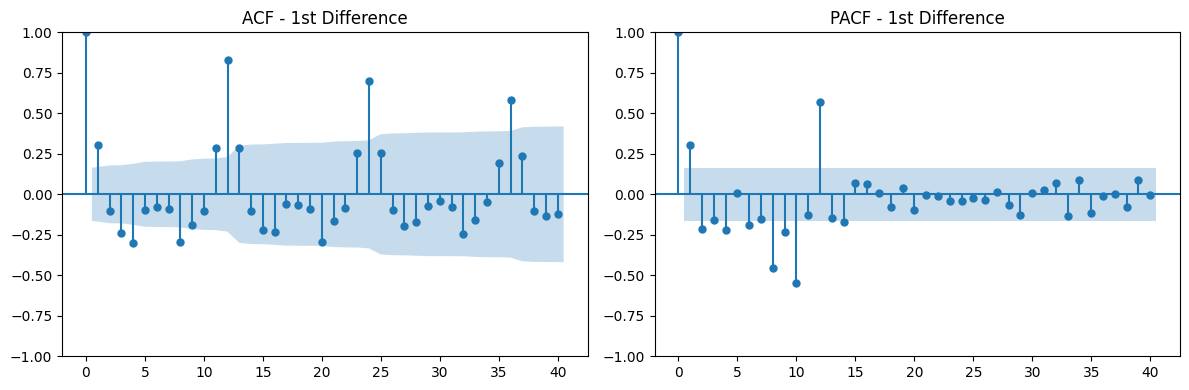

In [22]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
plot_acf(df_passengers["Passengers"].diff().dropna(), lags=40, ax=axes[0]) # ACF for 1st Difference
axes[0].set_title("ACF - 1st Difference")
plot_pacf(df_passengers["Passengers"].diff().dropna(), lags=40, ax=axes[1], method="ywm") # PACF for 1st Difference
axes[1].set_title("PACF - 1st Difference")
plt.tight_layout()
plt.show()

In [23]:
df_passengers.index.freq="MS"

p, d, q = 1, 1, 1
model = ARIMA(df_passengers["Passengers"], order=(p, d, q))  # (p, d, q)
arima_model = model.fit()

PACF გვიჩვენებს ძლიერ პიკს $Lag = 1$-თვის, მაშინ p = 1.

ACF გვიჩვენებს ძლიერ პიკს $Lag =1$-თვის, მაშინ q = 1 (seasonally = 12).

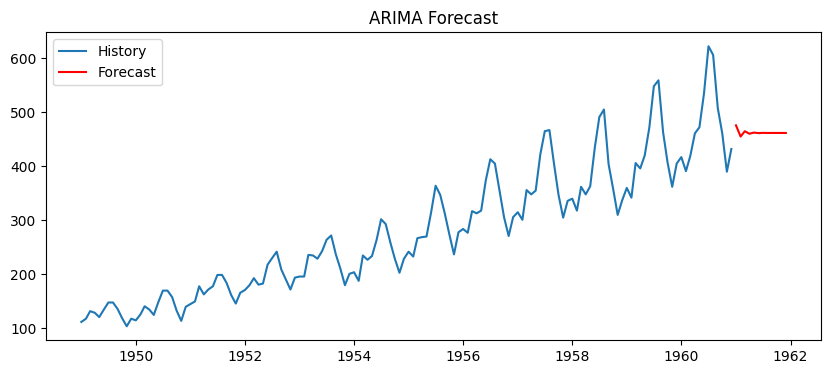

In [24]:
forecast = arima_model.forecast(steps=12)

plt.figure(figsize=(10, 4))
plt.plot(df_passengers["Passengers"], label="History")
plt.plot(forecast.index, forecast, label="Forecast", color="red")
plt.legend()
plt.title("ARIMA Forecast")
plt.show()

### SARIMA (Seasonal Autoregressive Integrated Moving Average)

| Parameter | Meaning                                                             |
| --------- | ------------------------------------------------------------------- |
| p     | Non-seasonal AR order (lag of past values)                          |
| d     | Non-seasonal differencing order (to make series stationary)         |
| q     | Non-seasonal MA order (lag of past residuals)                       |
| P     | Seasonal AR order (lag at multiples of s, e.g., 12 months)          |
| D     | Seasonal differencing order (to remove seasonal trend)              |
| Q     | Seasonal MA order (seasonal lag of residuals)                       |
| s     | Seasonal period (e.g., 12 for monthly data with yearly seasonality) |

In [25]:
# SARIMA parameters
p, d, q = 1, 1, 1
P, D, Q, s = 1, 1, 1, 12  # თვიური სეზონურობა

# Fit the SARIMA model
model = SARIMAX(df_passengers["Passengers"], order=(p, d, q), seasonal_order=(P, D, Q, s))
sarimax_model = model.fit()

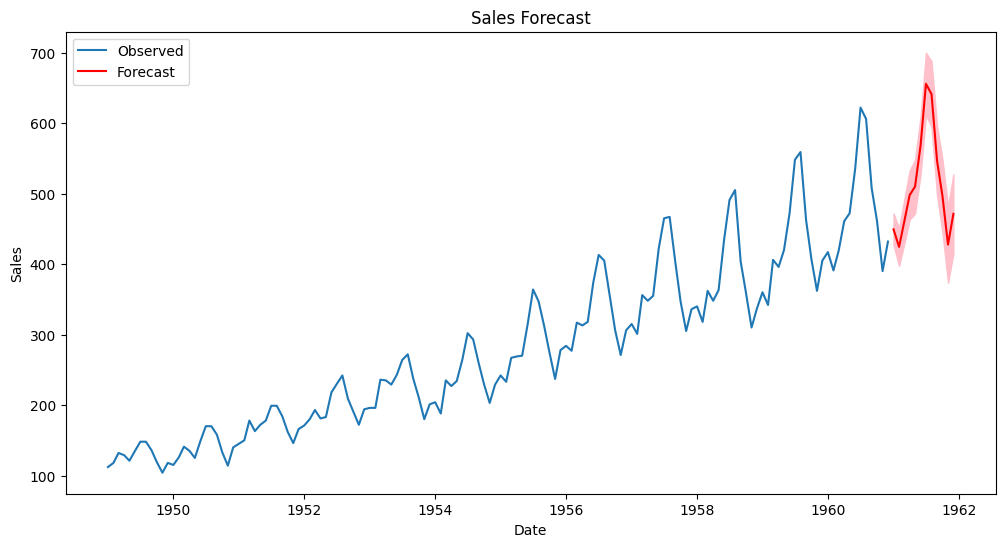

In [26]:
# Forecast future values
forecast_periods = 12  # Forecast the next 12 months
forecast = sarimax_model.get_forecast(steps=12)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

# Plot the forecast
plt.figure(figsize=(12, 6))
plt.plot(df_passengers["Passengers"], label="Observed")
plt.plot(forecast_mean, label="Forecast", color="red")
plt.fill_between(forecast_ci.index, forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color="pink")
plt.title("Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

| მახასიათებელი         | ARIMA                                                             | SARIMA                                                                |
| --------------------- | --------------------------------------------------------------------- | ------------------------------------------------------------------------- |
| სეზონურობა        | არ მოიცავს სეზონურობის მოდელირებას                              | ციკლურ (სეზონურ) შაბლონებს ითვალისწინებს                    |
| ფორმულა           | ARIMA(p, d, q)                                                        | SARIMA(p, d, q) × (P, D, Q, s)                                            |
| როდის გამოვიყენოთ | მონაცემები ტენდენციით, მაგრამ სეზონურობის გარეშე                  | მონაცემები ტენდენციით და სეზონურობით                                  |
| პარამეტრები       | `p` = AR, `d` = დიფერენცირება, `q` = MA                               | დამატებით: `P`, `D`, `Q` სეზონური კომპონენტებისთვის, `s` = სეზონის სიგრძე |
| მაგალითი          | ყოველთვიურად მზარდი გაყიდვები, მაგრამ გამეორებადი შაბლონის გარეშე | ყოველთვიურად განმეორებადი ფრენის მგზავრები                                |

### Facebook Prophet

Facebook Prophet დროით მწკრივს აღწერს როგორც რამდენიმე კომპონენტის ჯამს:

$$
y(t) = g(t) + s(t) + h(t) + \varepsilon_t
$$

სადაც:

| სიმბოლო | მნიშვნელობა |
|---|---|
| $y(t)$ | პროგნოზირებადი მნიშვნელობა დროის $t$ მომენტში |
| $g(t)$ | ტრენდი, ანუ გრძელვადიანი ზრდა ან კლება |
| $s(t)$ | სეზონურობა |
| $h(t)$ | დღესასწაულების ან სპეციალური მოვლენების ეფექტი |
| $\varepsilon_t$ | შემთხვევითი შეცდომა |

განხილული მონაცემებისათვის $y(t)$ არის ავიაკომპანიის მგზავრების რაოდენობა კონკრეტულ თვეში.

ამ მონაცემებისთვის მთავარი კომპონენტებია:

$$
y(t) = g(t) + s(t) + \varepsilon_t
$$

ამ მაგალითში დღესასწაულების ეფექტს ცალკე არ ვითვალისწინებთ.

რადგან მგზავრების რაოდენობასთან ერთად სეზონური რყევებიც იზრდება, გამოვიყენეთ multiplicative seasonality.

ამ შემთხვევაში მოდელი შეიძლება ასე ჩაიწეროს:

$$
y(t) = g(t) \cdot (1 + s(t)) + \varepsilon_t
$$

სადაც:

- $g(t)$ აღწერს მგზავრების რაოდენობის საერთო ზრდას დროთა განმავლობაში
- $s(t)$ აღწერს წლიურ სეზონურობას
- $\varepsilon_t$ არის მოდელის შეცდომა

Prophet სეზონურობას აღწერს Fourier series-ის გამოყენებით:

$$
s(t) = \sum_{n=1}^{N}
\left(
a_n \cos\left(\frac{2 \pi n t}{P}\right)
+
b_n \sin\left(\frac{2 \pi n t}{P}\right)
\right)
$$

სადაც:

| სიმბოლო | მნიშვნელობა |
|---|---|
| $P$ | სეზონის პერიოდი |
| $N$ | Fourier terms-ის რაოდენობა |
| $a_n, b_n$ | მოდელის მიერ ნასწავლი კოეფიციენტები |

ჩვენს შემთხვევაში სეზონურობა არის წლიური, ამიტომ:

$$
P = 12
$$

რადგან მონაცემები თვიურია და ერთი სრული სეზონი 12 თვეს მოიცავს.

ამ ამოცანაში Prophet ცდილობს მგზავრების რაოდენობა დაშალოს ორ მთავარ ნაწილად:

$$
\text{Passengers} =
\text{Trend}
+
\text{Yearly Seasonality}
+
\text{Error}
$$

ან multiplicative ფორმით:

$$
\text{Passengers} =
\text{Trend}
\cdot
(1 + \text{Yearly Seasonality})
+
\text{Error}
$$

ეს ნიშნავს, რომ მოდელი ერთდროულად სწავლობს:

1. როგორ იზრდება მგზავრების რაოდენობა წლების განმავლობაში
2. როგორ მეორდება სეზონური ცვლილებები ყოველ წელს
3. რა განსხვავებაა რეალურ და პროგნოზირებულ მნიშვნელობებს შორის

In [27]:
df_prophet = df_passengers.reset_index().rename(
    columns={
        "Timestamp": "ds",
        "Passengers": "y"
    }
)

# Split: train on all years except the last year
last_year = df_prophet["ds"].dt.year.max()

train = df_prophet[df_prophet["ds"].dt.year < last_year]
test = df_prophet[df_prophet["ds"].dt.year == last_year]

In [28]:
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode="multiplicative"
)

model.fit(train)

# Predict only the last year
future = test[["ds"]]

forecast = model.predict(future)

result = test.merge(
    forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds"
)

20:57:59 - cmdstanpy - INFO - Chain [1] start processing
20:58:00 - cmdstanpy - INFO - Chain [1] done processing


In [29]:
mae = mean_absolute_error(result["y"], result["yhat"])
rmse = np.sqrt(mean_squared_error(result["y"], result["yhat"]))
mape = np.mean(np.abs((result["y"] - result["yhat"]) / result["y"])) * 100

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

MAE:  22.03
RMSE: 25.95
MAPE: 4.47%


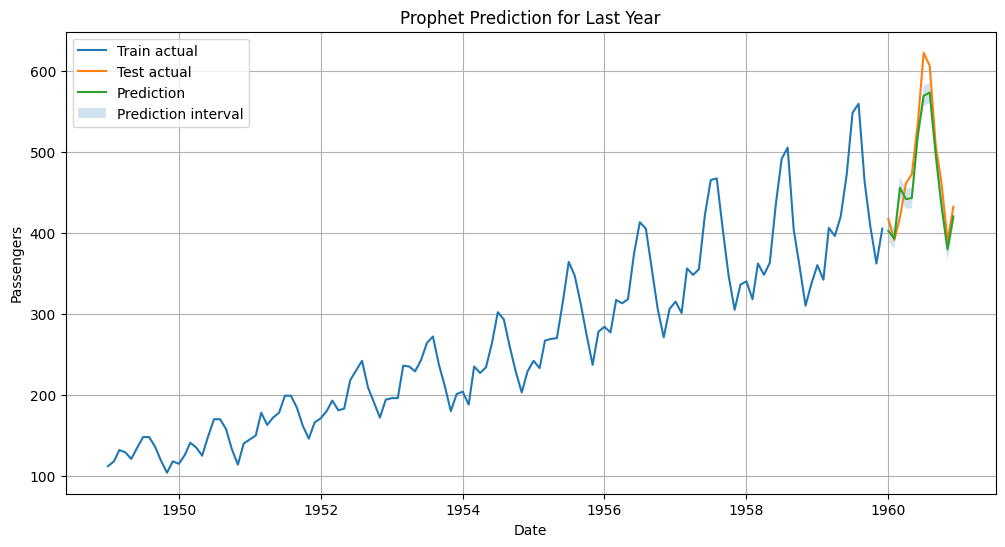

In [30]:
plt.figure(figsize=(12, 6))

plt.plot(train["ds"], train["y"], label="Train actual")
plt.plot(test["ds"], test["y"], label="Test actual")
plt.plot(result["ds"], result["yhat"], label="Prediction")

plt.fill_between(
    result["ds"],
    result["yhat_lower"],
    result["yhat_upper"],
    alpha=0.2,
    label="Prediction interval"
)

plt.title("Prophet Prediction for Last Year")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()
plt.grid(True)
plt.show()

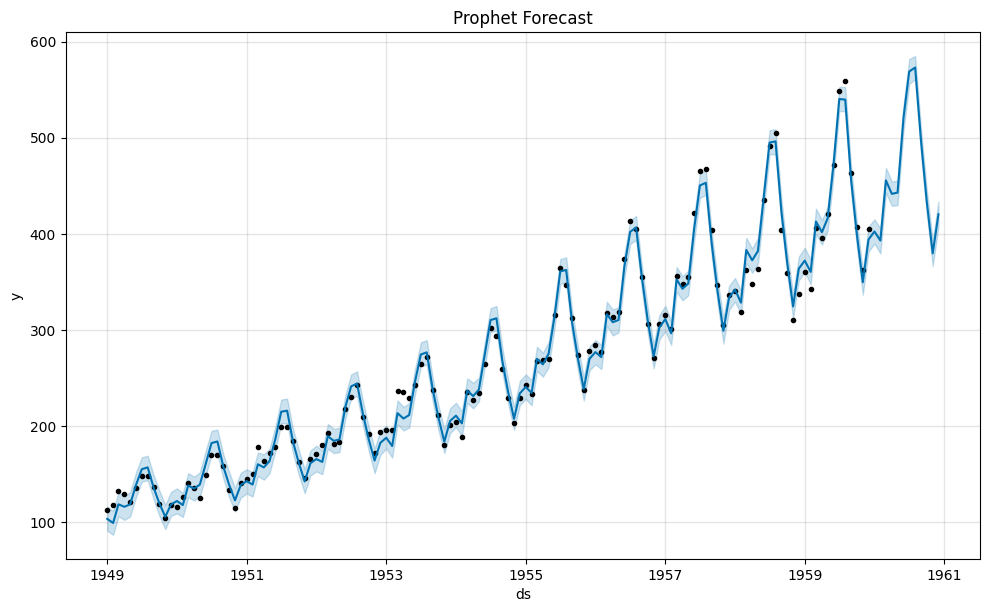

In [31]:
full_future = model.make_future_dataframe(periods=12, freq="MS")
full_forecast = model.predict(full_future)

fig = model.plot(full_forecast)
plt.title("Prophet Forecast")
plt.show()

#### The Bitcoin Price Over Time

In [32]:
# მონაცემების ჩატვირთვა
data_path = "../../datasets/bitcoin/BTC_USD Bitfinex Historical Data.csv"
df_bitcoin = pd.read_csv(data_path, parse_dates=["Date"])
df_bitcoin = df_bitcoin.set_index("Date")
df_bitcoin.head()

,Price,Open,High,Low,Vol.,Change %
Date,,,,,,
2018-09-19,"6,288.5","6,330.8","6,364.9","6,257.1",14.60K,-0.86%
2018-09-18,"6,342.8","6,243.0","6,384.0","6,229.2",15.93K,1.42%
2018-09-17,"6,254.2","6,506.1","6,532.8","6,205.1",23.54K,-3.76%
2018-09-16,"6,498.5","6,512.8","6,517.8","6,384.5",8.73K,-0.23%
2018-09-15,"6,513.6","6,480.1","6,568.9","6,473.6",8.35K,0.44%


In [33]:
# შევამოწმოთ მონაცემები ზრდის მიხედვით თუა დალაგებული
df_bitcoin.index.is_monotonic_increasing

False

In [34]:
# დავალაგოთ ინდექსის მიხედვით
df_bitcoin = df_bitcoin.sort_index()

In [35]:
# შევამოწმოთ მონაცემები ზრდის მიხედვით თუა დალაგებული
df_bitcoin.index.is_monotonic_increasing

True

In [36]:
# ინდექსით მონაცემებზე წვდომა
df_bitcoin.loc["2018-01"]

,Price,Open,High,Low,Vol.,Change %
Date,,,,,,
2018-01-01,"13,354.0","13,794.0","13,893.0","12,787.0",29.54K,-3.23%
2018-01-02,"14,709.8","13,448.0","15,300.0","12,810.0",56.18K,10.15%
2018-01-03,"15,155.0","14,713.0","15,428.0","14,522.0",38.35K,3.03%
2018-01-04,"15,160.0","15,150.0","15,390.0","14,064.0",46.47K,0.03%
2018-01-05,"16,917.0","15,159.0","17,101.0","14,769.0",54.63K,11.59%
2018-01-06,"17,161.0","16,911.0","17,252.0","16,251.0",29.61K,1.44%
2018-01-07,"16,196.0","17,163.0","17,176.0","15,726.0",30.84K,-5.62%
2018-01-08,"14,930.0","16,216.0","16,279.0","13,760.0",64.95K,-7.82%
2018-01-09,"14,423.0","14,902.0","15,355.0","14,122.0",43.44K,-3.40%


In [37]:
# ინდექსით მონაცემებზე წვდომა
df_bitcoin.loc["January 2018"]

,Price,Open,High,Low,Vol.,Change %
Date,,,,,,
2018-01-01,"13,354.0","13,794.0","13,893.0","12,787.0",29.54K,-3.23%
2018-01-02,"14,709.8","13,448.0","15,300.0","12,810.0",56.18K,10.15%
2018-01-03,"15,155.0","14,713.0","15,428.0","14,522.0",38.35K,3.03%
2018-01-04,"15,160.0","15,150.0","15,390.0","14,064.0",46.47K,0.03%
2018-01-05,"16,917.0","15,159.0","17,101.0","14,769.0",54.63K,11.59%
2018-01-06,"17,161.0","16,911.0","17,252.0","16,251.0",29.61K,1.44%
2018-01-07,"16,196.0","17,163.0","17,176.0","15,726.0",30.84K,-5.62%
2018-01-08,"14,930.0","16,216.0","16,279.0","13,760.0",64.95K,-7.82%
2018-01-09,"14,423.0","14,902.0","15,355.0","14,122.0",43.44K,-3.40%


In [38]:
# Preprocessing
df_bitcoin["Price"] = df_bitcoin["Price"].str.replace(",", "").astype("float")

<Axes: xlabel='Date'>

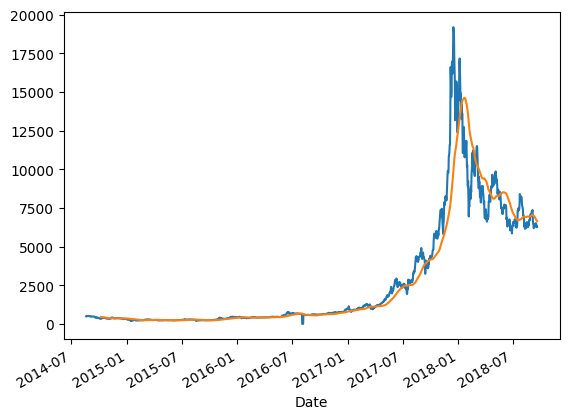

In [39]:
df_bitcoin["Price"].plot(kind="line")
# df_bitcoin["Price"].resample("2w").median().plot(kind="line")
df_bitcoin["Price"].rolling(50).mean().plot(kind="line") # moving average

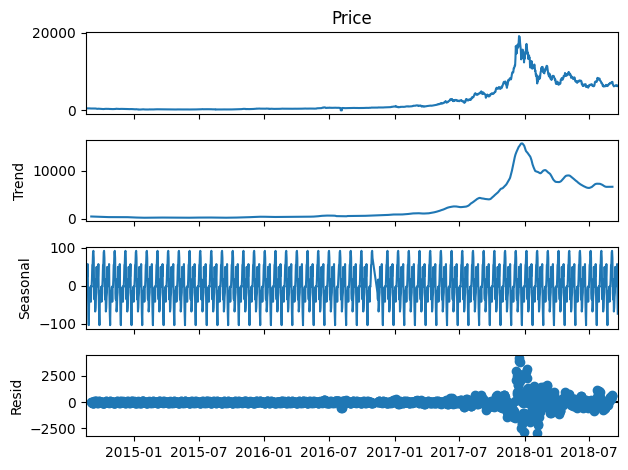

In [40]:
result = seasonal_decompose(df_bitcoin["Price"], model="additive", period=30)
result.plot();

#### Stock data

| სვეტი      | აღწერა                                                                           |
| ---------- | -------------------------------------------------------------------------------- |
| Date   | სავაჭრო სესიის თარიღი                                                         |
| Open   | აქციის ფასი სავაჭრო ბაზრის გახსნისას                          |
| High   | ყველაზე მაღალი ფასი, რომელსაც აქციამ მიაღწია                |
| Low    | ყველაზე დაბალი ფასი, რომელსაც აქციამ მიაღწია                 |
| Close  | აქციის ფასი ბაზრის დახურვისას                            |
| Volume | აქციების საერთო რაოდენობა, რომელიც დღეს განმავლობაში გაიყიდა |

In [41]:
# მონაცემების ჩატვირთვა
df_stock = pd.read_excel("../../datasets/vonovia/Historical_Data_Vonovia.xlsx")
df_stock.round(3).head()

,Date,Open,High,Low,Close,Volume
0,11.07.2013,15.193,15.638,15.167,15.593,3679224.570
1,12.07.2013,15.567,15.966,15.549,15.638,510410.653
2,15.07.2013,15.726,16.029,15.593,16.029,361133.264
3,16.07.2013,16.144,16.437,15.966,15.993,272958.839
4,17.07.2013,16.215,16.215,15.904,16.126,1154373.321


In [42]:
print(f"Missing values in Data: \n{df_stock.isna().sum()}")

Missing values in Data: 
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [43]:
print(f"Duplicates in Data: {df_stock.duplicated().sum()}")

Duplicates in Data: 0


In [44]:
print("Data types:")
print(df_stock.dtypes)

Data types:
Date       object
Open      float64
High      float64
Low       float64
Close     float64
Volume    float64
dtype: object


In [45]:
# Descriptive Statistics
df_stock.describe().round()

,Open,High,Low,Close,Volume
count,2894.0,2894.0,2894.0,2894.0,2894.0
mean,33.0,34.0,33.0,33.0,1737317.0
std,11.0,11.0,11.0,11.0,1581270.0
min,15.0,16.0,15.0,16.0,1571.0
25%,25.0,26.0,25.0,25.0,1047957.0
50%,31.0,31.0,31.0,31.0,1449158.0
75%,42.0,42.0,41.0,41.0,2085477.0
max,59.0,59.0,58.0,58.0,30923963.0


In [46]:
df_stock["Date"] = pd.to_datetime(df_stock["Date"], format="%d.%m.%Y")
df_stock["Year"] = df_stock["Date"].dt.year
df_stock.Year.value_counts().reset_index()

,Year,count
0,2022,257
1,2016,255
2,2021,255
3,2023,255
4,2020,254
5,2015,253
6,2014,252
7,2018,251
8,2019,251
9,2017,249


In [47]:
df_stock = df_stock[df_stock["Year"] > 2013].reset_index(drop=True)

In [48]:
# აქციის ყოველდღიური შემოსავალი: ის გამოხატავს დახურვის ფასის პროცენტულ ცვლილებას წინა დღესთან შედარებით (მოგება/წაგება)
df_stock["Daily_Returns"] = df_stock["Close"].pct_change()  

# 5-დღიანი rolling window-თი გამოთვლილი სტანდარტული გადახრა: აჩვენებს აქციის ფასის მერყეობას — რაც რისკის ინდიკატორია
df_stock["Volatility"] = df_stock["Daily_Returns"].rolling(window=5).std()
  
# დღის მაქსიმუმსა და მინიმუმს შორის სხვაობა — ამ დღის ფასის დიაპაზონი
df_stock["Price_Range"] = df_stock["High"] - df_stock["Low"]

# დღის განმავლობაში ფასის ცვლილება გახსნიდან დახურვამდე
df_stock["Price_Change"] = df_stock["Close"] - df_stock["Open"]  
 
# დახურვის ფასის 50-დღიანი მარტივი მოძრავი საშუალო (MA)
df_stock["MA_50"] = df_stock["Close"].rolling(window=50).mean() 

# დახურვის ფასის 200-დღიანი მარტივი მოძრავი საშუალო (MA)
df_stock["MA_200"] = df_stock["Close"].rolling(window=200).mean()  

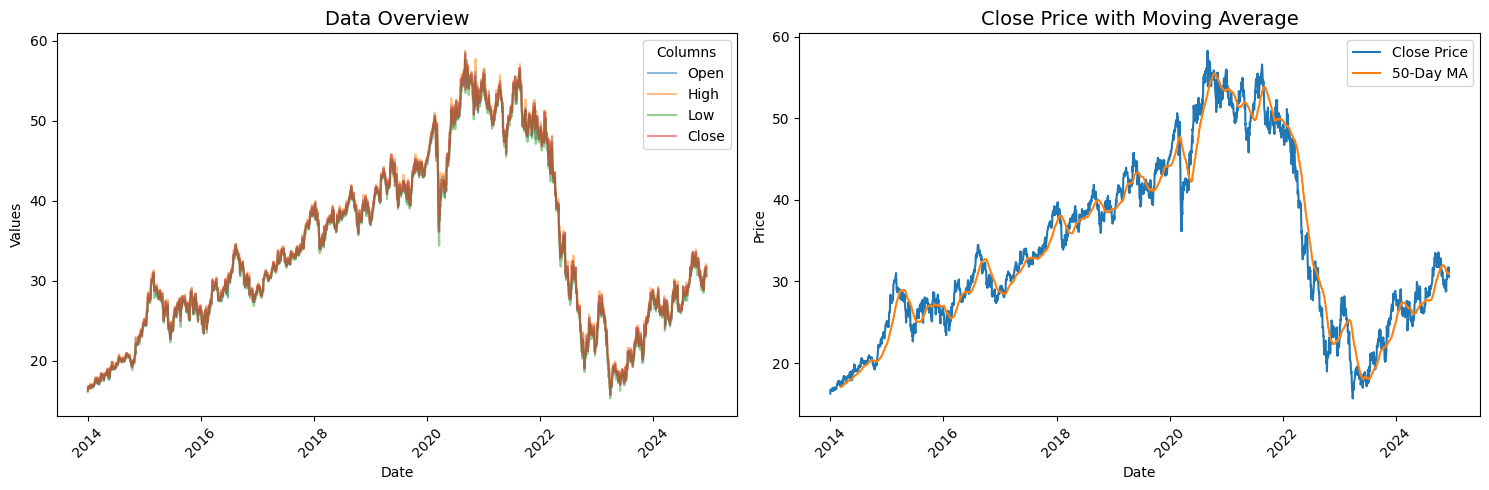

In [49]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

for col in df_stock.columns[1:5]:
    axes[0].plot(df_stock["Date"], df_stock[col], label=col, alpha=0.5)
axes[0].set_title("Data Overview", fontsize=14)
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Values")
axes[0].legend(title="Columns")
axes[0].tick_params(axis="x", rotation=45)

# Close Price and Moving Average
axes[1].plot(df_stock["Date"], df_stock["Close"], label="Close Price")
axes[1].plot(df_stock["Date"], df_stock["MA_50"], label="50-Day MA")
axes[1].set_title("Close Price with Moving Average", fontsize=14)
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Price")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

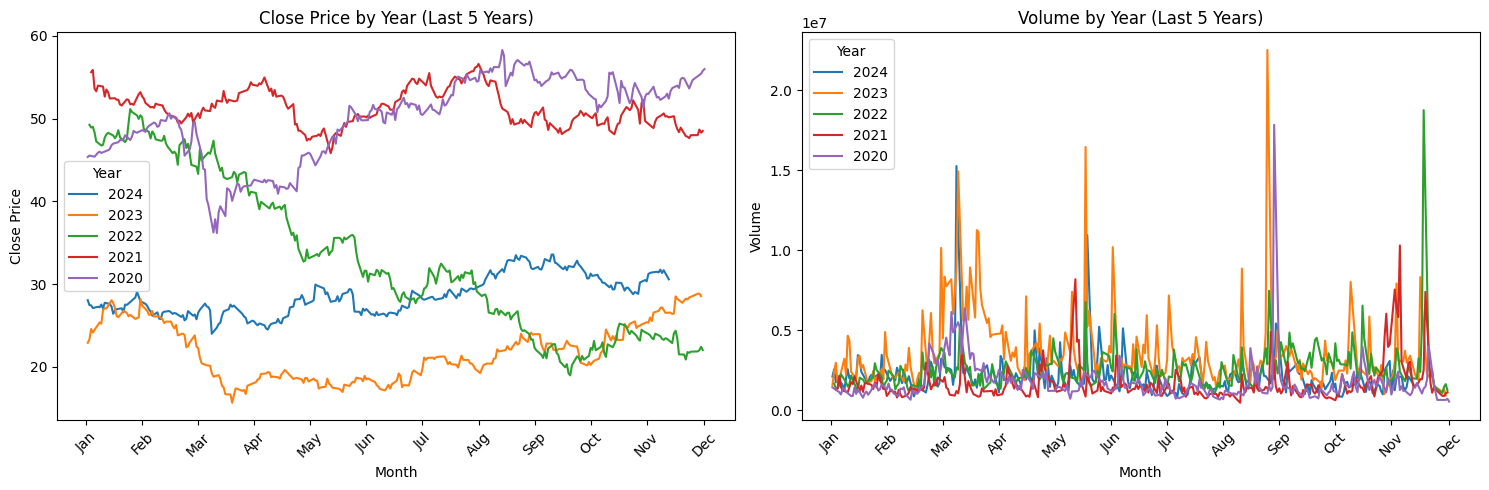

In [50]:
# ბოლო 5 წლის მონაცემები შევადაროთ
last_5_years = sorted(df_stock["Year"].unique(), reverse=True)[:5]
df_last_5_years = df_stock[df_stock["Year"].isin(last_5_years)]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

# Close price
for year in last_5_years:
    yearly_data = df_last_5_years[df_last_5_years["Year"] == year]
    axes[0].plot(
        yearly_data["Date"].dt.dayofyear,
        yearly_data["Close"],
        label=str(year)
    )

axes[0].set_title("Close Price by Year (Last 5 Years)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Close Price")
axes[0].set_xticks(np.linspace(1, 365, 12, dtype=int))
axes[0].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", 
                         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], rotation=45)
axes[0].legend(title="Year")

# შეძენილი / გაყიდული აქციების რაოდენობა
for year in last_5_years:
    yearly_data = df_last_5_years[df_last_5_years["Year"] == year]
    axes[1].plot(
        yearly_data["Date"].dt.dayofyear,
        yearly_data["Volume"],
        label=str(year)
    )

axes[1].set_title("Volume by Year (Last 5 Years)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Volume")
axes[1].set_xticks(np.linspace(1, 365, 12, dtype=int))
axes[1].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", 
                         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], rotation=45)
axes[1].legend(title="Year")

plt.tight_layout()
plt.show()

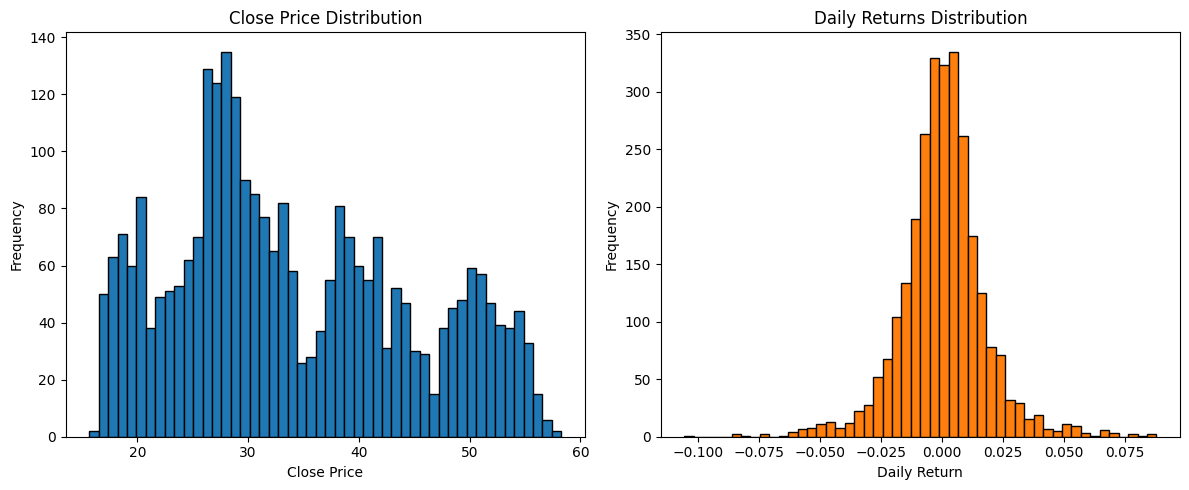

In [51]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# აქციების ფასის განაწილება
axes[0].hist(df_stock["Close"].dropna(), bins=50, edgecolor="black", color="C0")
axes[0].set_title("Close Price Distribution")
axes[0].set_xlabel("Close Price")
axes[0].set_ylabel("Frequency")

# დღიური მოგების განაწილების გრაფიკი
axes[1].hist(df_stock["Daily_Returns"].dropna(), bins=50, edgecolor="black", color="C1")
axes[1].set_title("Daily Returns Distribution")
axes[1].set_xlabel("Daily Return")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

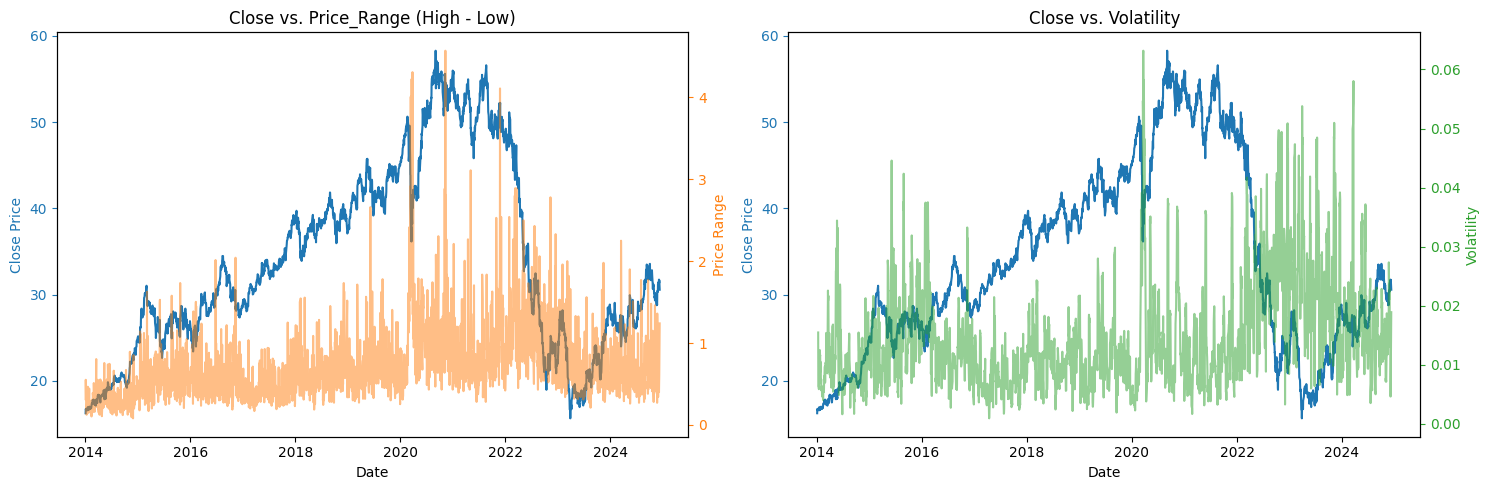

In [52]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

# Close vs. Price Range ---
ax1 = axes[0]
ax1.plot(df_stock["Date"], df_stock["Close"], color="C0")
ax1.set_ylabel("Close Price", color="C0")
ax1.tick_params(axis="y", colors="C0")
ax1.set_title("Close vs. Price_Range (High - Low)")
ax1.set_xlabel("Date")

ax1b = ax1.twinx()
ax1b.plot(df_stock["Date"], df_stock["Price_Range"], color="C1", alpha=0.5)
ax1b.set_ylabel("Price Range", color="C1")
ax1b.tick_params(axis="y", colors="C1")

# Close vs. Volatility ---
ax2 = axes[1]
ax2.plot(df_stock["Date"], df_stock["Close"], color="C0")
ax2.set_ylabel("Close Price", color="C0")
ax2.tick_params(axis="y", colors="C0")
ax2.set_title("Close vs. Volatility")
ax2.set_xlabel("Date")

ax2b = ax2.twinx()
ax2b.plot(df_stock["Date"], df_stock["Volatility"], color="C2", alpha=0.5)
ax2b.set_ylabel("Volatility", color="C2")
ax2b.tick_params(axis="y", colors="C2")

plt.tight_layout()
plt.show()

In [53]:
# Predict stock price
# Close price forecast for 2024
hist_data = df_stock[df_stock["Year"] < 2024].set_index("Date")["Close"] # აქციების ფასი 2024 წლამდე
actual_2024 = df_stock[(df_stock["Year"] == 2024)].set_index("Date")["Close"] # აქციების ფასი 2024 წელს

In [54]:
# ვამოწმებთ სტაციონარობას
result = adfuller(hist_data)
print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -1.7159487058770357
p-value: 0.4229145228602844


| კრიტერიუმი                                                | ინტერპრეტაცია                                                                  |
| --------------------------------------------------------- | ------------------------------------------------------------------------------ |
| p-value > 0.05                                      | არ არის სტაციონარული |

საჭიროა სერიის სტაციონარიზაცია დიფერენცირებით:

In [55]:
close_diff = hist_data.diff().dropna()

adf_result = adfuller(close_diff)
print(f"ADF Statistic: {adf_result[0]}")
print(f"p-value: {adf_result[1]}")

ADF Statistic: -52.120923755915
p-value: 0.0


p-value < 0.05, ერთხელ დიფერენცირება საკმარისი აღმოჩნდა, ანუ d = 1.

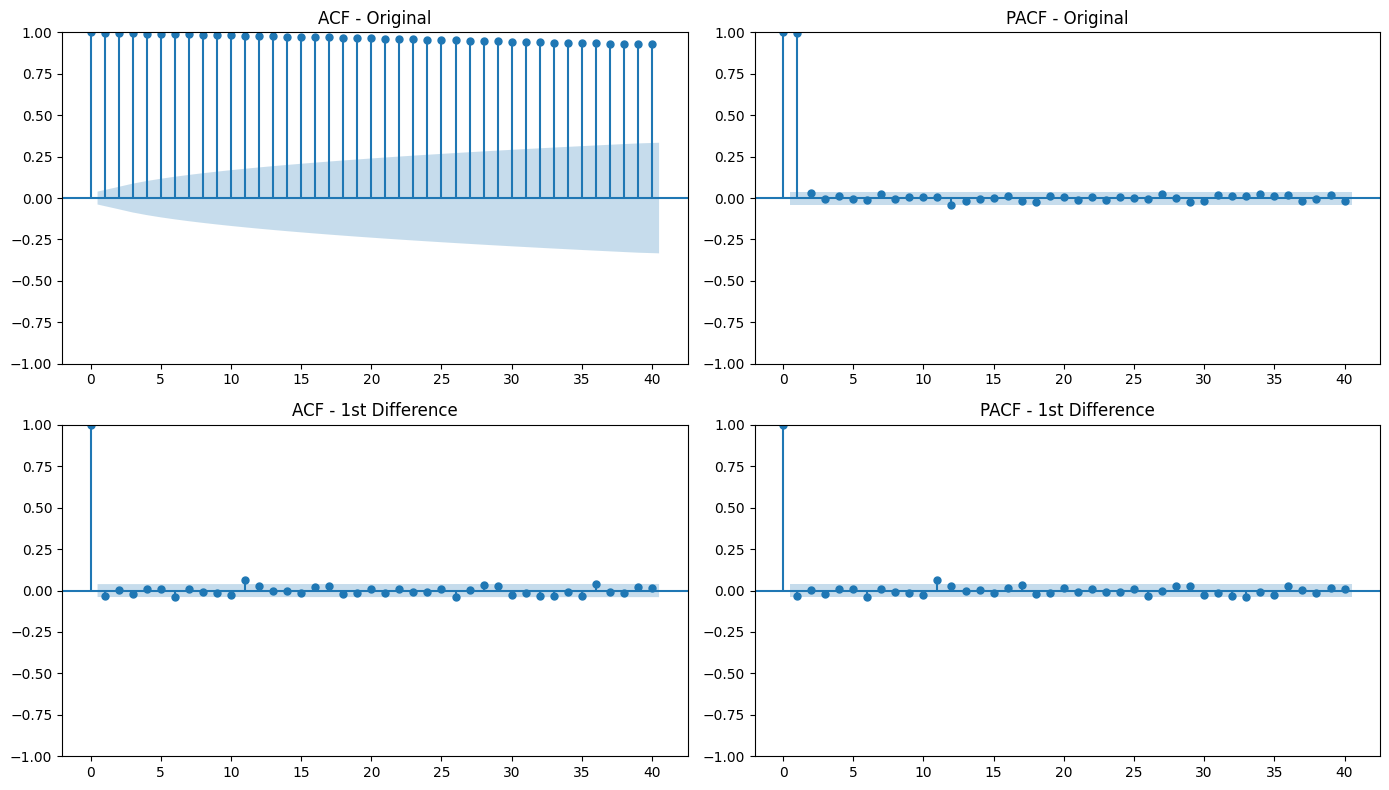

In [56]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8))

# ACF - Original
plot_acf(hist_data.dropna(), lags=40, ax=axes[0, 0])
axes[0, 0].set_title("ACF - Original")

# PACF - Original
plot_pacf(hist_data.dropna(), lags=40, ax=axes[0, 1], method="ywm") # გამოიყენება AR (p) პარამეტრის დასადგენად, ანუ რამდენი წარსული მნიშვნელობა ახდენს გავლენას.
axes[0, 1].set_title("PACF - Original")

# ACF - 1st Difference
plot_acf(hist_data.diff().dropna(), lags=40, ax=axes[1, 0])  # გამოიყენება MA (q) პარამეტრის დასადგენად.
axes[1, 0].set_title("ACF - 1st Difference")

# PACF - 1st Difference
plot_pacf(hist_data.diff().dropna(), lags=40, ax=axes[1, 1], method="ywm")
axes[1, 1].set_title("PACF - 1st Difference")

plt.tight_layout()
plt.show()

/Users/tsitsitepnadze/Library/Caches/pypoetry/virtualenvs/ds-playground-WjJNrmro-py3.13/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.

/Users/tsitsitepnadze/Library/Caches/pypoetry/virtualenvs/ds-playground-WjJNrmro-py3.13/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.

/Users/tsitsitepnadze/Library/Caches/pypoetry/virtualenvs/ds-playground-WjJNrmro-py3.13/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.

/Users/tsitsitepnadze/Library/Caches/pypoetry/virtualenvs/ds-playground-WjJNrmro-py3.13/lib/python3.13/site-p

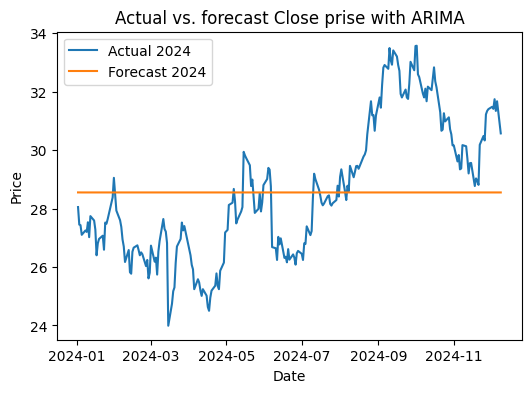

In [57]:
# ARIMA
model = ARIMA(hist_data, order=(1,1,1))
results = model.fit()

forecast = results.forecast(steps=len(actual_2024)) # 242 actual წერტილი გვაქვს 

# პროგნოზის და ნამდვილი მნიშვნელობების შედარება
plt.figure(figsize=(6,4))
plt.plot(actual_2024.index, actual_2024, label="Actual 2024")
plt.plot(actual_2024.index, forecast, label="Forecast 2024")
plt.title("Actual vs. forecast Close prise with ARIMA")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

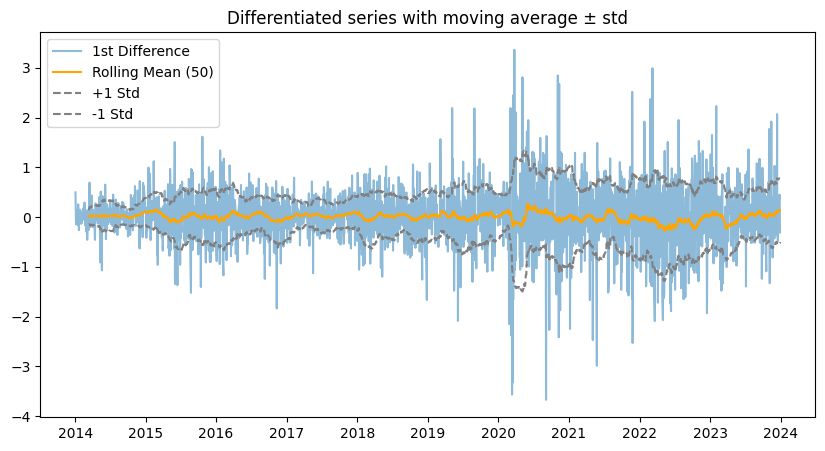

In [58]:
diff = hist_data.diff()

plt.figure(figsize=(10,5))
plt.plot(diff, label="1st Difference", alpha=0.5)
plt.plot(diff.rolling(50).mean(), label="Rolling Mean (50)", color="orange")
plt.plot(diff.rolling(50).mean() + diff.rolling(50).std(), linestyle="--", color="gray", label="+1 Std")
plt.plot(diff.rolling(50).mean() - diff.rolling(50).std(), linestyle="--", color="gray", label="-1 Std")
plt.legend()
plt.title("Differentiated series with moving average ± std")
plt.show()

In [59]:
# seasonal_decompose-ს სჭირდება period არგუმენტი, გავარკვიოთ რა მნიშვნელობა გადავცეთ
print(np.mean([len(df_stock[df_stock["Year"] == year]) for year in df_stock["Year"].unique()], dtype=int))

252


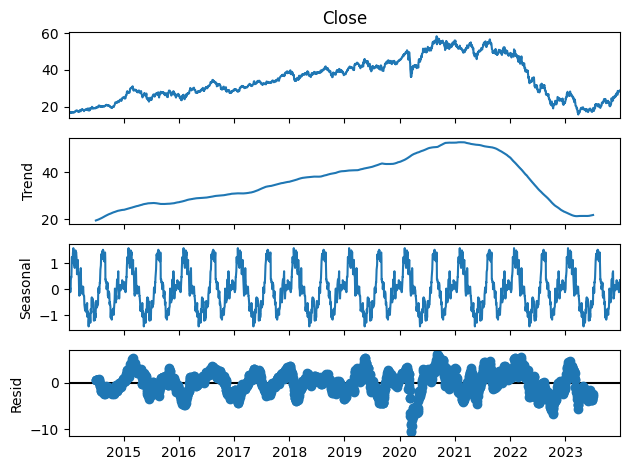

In [60]:
# ტრენდისა და სეზონური ფაქტორის გამოყოფა
decomposition = seasonal_decompose(hist_data, model="additive", period=252)
fig = decomposition.plot()
plt.show()

Additive Model: $Y_t = T_t + S_t + R_t$

/Users/tsitsitepnadze/Library/Caches/pypoetry/virtualenvs/ds-playground-WjJNrmro-py3.13/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.

/Users/tsitsitepnadze/Library/Caches/pypoetry/virtualenvs/ds-playground-WjJNrmro-py3.13/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.



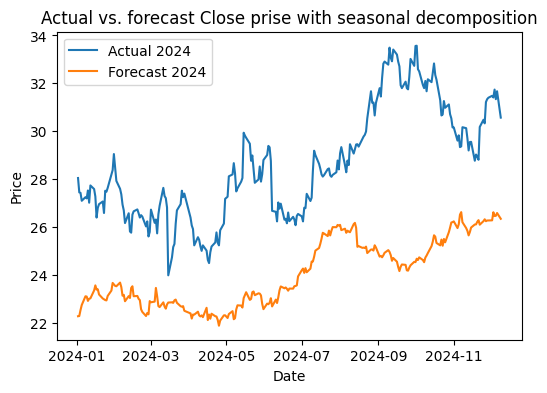

In [61]:
l = len(actual_2024)
# გამოვყოფოთ კომპონენტები
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

# სამომავლო ტრენდის პროგნოზირება
trend_model = ExponentialSmoothing(trend.dropna(), trend="add", seasonal=None, seasonal_periods=None)
trend_fit = trend_model.fit()
trend_forecast = trend_fit.forecast(steps=l)

# სეზონური ეფექტის გათვალისწინება
seasonal_forecast = np.tile(seasonal[-252:-252+l].values, 1)

# Additive model
forecast = trend_forecast + seasonal_forecast

plt.figure(figsize=(6, 4))
plt.plot(actual_2024.index, actual_2024, label="Actual 2024")
plt.plot(actual_2024.index, forecast, label="Forecast 2024")
plt.title("Actual vs. forecast Close prise with seasonal decomposition")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

In [62]:
# ევალუაციის მეტრიკები მოდელის შესაფასებლად
mae = mean_absolute_error(forecast[:len(actual_2024)], actual_2024)
rmse = np.sqrt(mean_squared_error(forecast[:len(actual_2024)], actual_2024))
mape = np.mean(np.abs((actual_2024.values - forecast[:len(actual_2024)]) / actual_2024.values)) * 100

print(f"Mean Absolute Error (MAE): {np.round(mae, 2)}")
print(f"Root Mean Squared Error (RMSE): {np.round(rmse, 2)}")
print(f"Mean Absolute Percentage Error (MAPE): {np.round(mape, 2)}%")

Mean Absolute Error (MAE): 4.51
Root Mean Squared Error (RMSE): 4.84
Mean Absolute Percentage Error (MAPE): 15.51%


#### XGBRegressor

XGBoost არ მუშაობს პირდაპირ დროის სერიებზე, მაგრამ შესაძლებელია მონაცემების გარდაქმნის შემდეგ ის გამოვიყენოთ. 
თითოეული მონაცემისთვის ვამატებთ ინფორმაციას წარსულიდან (Lag-Features).

Feature Engineering-ის შემდეგ:
| y(t-1) | y(t-2) | y(t-7) | week day    | month | holiday |
| ------ | ------ | ------ | ------------- | --- | ----------- |
| 123.5  | 125.2  | 130.0  | 1  | 4   | 0           |

---- 
| Feature                      | **ARIMA**                       | **XGBoost**                                           |
| ---------------------------- | ------------------------------- | ----------------------------------------------------- |
| Time Awareness         | Built-in (AR, MA, Diff) | Must be added manually via lag features         |
| Linear Model        | Yes                             | No (nonlinear, tree-based)                            |
| Learning Capacity    | Limited                         | Yes (can learn complex patterns)                      |
| Feature Engineering  | Not possible                    | Very flexible (e.g., weekday, holiday, seasons, etc.) |
| Model Complexity      | Simple, interpretable           | More complex, harder to interpret                     |
| Stationarity Required | Yes                             | No                                                    |

In [63]:
def create_lag_features(series, lags=[1, 2, 7]):
    df = pd.DataFrame({"y": series})
    for lag in lags:
        df[f"lag_{lag}"] = df["y"].shift(lag)
    return df.dropna()

In [64]:
hist_data = create_lag_features(hist_data)
actual_2024 = create_lag_features(actual_2024)

hist_data.iloc[:8]

,y,lag_1,lag_2,lag_7
Date,,,,
2014-01-13,16.748,16.615,16.677,16.246
2014-01-14,16.748,16.748,16.615,16.744
2014-01-15,16.584,16.748,16.748,16.602
2014-01-16,16.699,16.584,16.748,16.686
2014-01-17,16.957,16.699,16.584,16.775
2014-01-20,16.921,16.957,16.699,16.677
2014-01-21,16.659,16.921,16.957,16.615
2014-01-22,16.659,16.659,16.921,16.748


In [65]:
X_train, y_train = hist_data.drop("y", axis=1), hist_data["y"]
X_test, y_test = actual_2024.drop("y", axis=1), actual_2024["y"]

In [66]:
model = XGBRegressor(n_estimators=100)
model.fit(X_train, y_train)

forecast = model.predict(X_test)

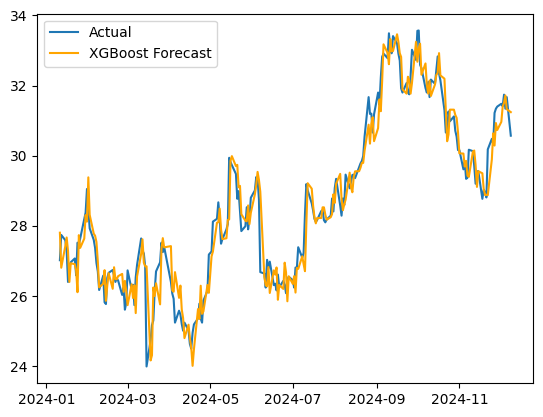

In [67]:
plt.plot(y_test.index, y_test, label="Actual")
plt.plot(y_test.index, forecast, label="XGBoost Forecast", color="orange")
plt.legend()
plt.show()

| სიტუაცია                               | რეკომენდაცია  |
| -------------------------------------- | ------------- |
| მონაცემები არ არის სტაციონარული        | XGBoost     |
| ბევრი გარე ფაქტორი გვაქვს               | XGBoost     |
| არაწრფივი ტენდენციებია               | XGBoost     |
| პროგნოზი მრავალი ნაბიჯით         | XGBoost     |
| მარტივი, ინტერპრეტირებადი მოდელი | ARIMA |

##### გამოვიკვლიოთ რამდენად მყარია ამ კომპანიის აქციების კურსი ბაზრის ზოგად მდგომარეობასთან მიმართებაში
yfinance-ს მეშვეობით შესაძლებელია ფინანსური მონაცემების ჩამოტვირთვა — მაგალითად, აქციის ფასები, სავაჭრო მოცულობები, დივიდენდები, და ა.შ.

გამოვიყენოთ yfinance ჩვენს მონაცემებზე ეკონომიკური ინდექსების შესადარებლად

In [68]:
# Risk analysis
vonovia = yf.Ticker("VNA.DE")
dax = yf.Ticker("^GDAXI") # DAX (Deutscher Aktienindex - გერმანული აქციების ინდექსი)

vonovia_data = vonovia.history(period="1y")
dax_data = dax.history(period="1y")

vonovia_returns = vonovia_data["Close"].pct_change().dropna()
vonovia_volatility = vonovia_returns.std() * np.sqrt(252)
print(f"Volatility of Vonovia: {vonovia_volatility:.4f}")

dax_returns = dax_data["Close"].pct_change().dropna()
covariance = vonovia_returns.cov(dax_returns)
dax_variance = dax_returns.var()
beta = covariance / dax_variance
print(f"Beta of Vonovia versus DAX: {beta:.4f}")

var_95 = vonovia_returns.quantile(0.05)
print(f"Value at Risk (VaR) of Vonovia: {var_95:.4f}")

Volatility of Vonovia: 0.2717
Beta of Vonovia versus DAX: 0.8459
Value at Risk (VaR) of Vonovia: -0.0253


**Volatility of Vonovia = 0.2717**

ეს ნიშნავს, რომ Vonovia-ს აქციის ფასი საშუალოდ წელიწადში დაახლოებით **27.17%-ით** მერყეობს მის საშუალო მნიშვნელობასთან შედარებით. რაც უფრო მაღალია volatility, მით უფრო მაღალია ფასის მერყეობა და შესაბამისად საინვესტიციო რისკიც.

---

**Beta of Vonovia versus DAX = 0.8459**

Beta ზომავს, რამდენად რეაგირებს აქცია ბაზრის, ამ შემთხვევაში DAX-ის, მოძრაობებზე.

Beta = **0.8459** ნიშნავს, რომ Vonovia-ს აქცია, როგორც წესი, DAX-ის მიმართულებით მოძრაობს, მაგრამ შედარებით ნაკლები მგრძნობელობით. რადგან beta ნაკლებია 1-ზე, Vonovia-ს აქცია ბაზრის ცვლილებებზე საშუალოდ უფრო სუსტად რეაგირებს, ვიდრე თავად DAX.

მაგალითად, თუ DAX გაიზრდება 1%-ით, Vonovia-ს აქცია საშუალოდ შეიძლება გაიზარდოს დაახლოებით 0.85%-ით. თუ DAX შემცირდება 1%-ით, Vonovia-ს აქცია საშუალოდ შეიძლება შემცირდეს დაახლოებით 0.85%-ით.

ეს მიუთითებს, რომ Vonovia-ს ბაზართან დაკავშირებული რისკი შედარებით დაბალია DAX-თან შედარებით, თუმცა აქციას მაინც შეიძლება ჰქონდეს სხვა სპეციფიკური რისკები.

---

**Value at Risk (VaR) of Vonovia = -0.0253**

ეს ნიშნავს, რომ არსებობს **5%-იანი ალბათობა** ანუ დაახლოებით 1 დღე 20-დან, როცა Vonovia-ს დღიური დანაკარგი შეიძლება აღემატებოდეს **-2.53%-ს**.

სხვა სიტყვებით, **95%-იანი სანდოობით**, ერთი დღის განმავლობაში მოსალოდნელი დანაკარგი არ იქნება მეტი, ვიდრე ინვესტიციის დაახლოებით **2.53%**.

მაგალითად, თუ ინვესტიცია არის 10,000 ევრო, მაშინ 2.53% შეადგენს დაახლოებით 253 ევროს. ანუ 95%-იანი სანდოობით, ერთ დღეში დანაკარგი არ გადააჭარბებს დაახლოებით 253 ევროს, თუმცა 5%-იან შემთხვევაში დანაკარგი შეიძლება უფრო დიდი იყოს.


შესაძლო დამატებითი ანალიზი:
1. აქციას ფასისა და სხვა ეკონომიკურ მაჩვენებლებს შორის კავშირის იდენტიფიცირება, მაგალითად თუ როგორ მოქმედებს საპროცენტო განაკვეთების ზრდა ან კლება აქციის ფასზე.
მომატებული საპროცენტო განაკვეთი ზრდის იპოთეკის ხარჯებს, რაც ამცირებს უძრავი ქონების მოთხოვნას — ეს კი შეიძლება უარყოფითად აისახოს აქციის ფასზე.

უძრავი ქონების ფასები:
თუ უძრავი ქონების ბაზარი იაფდება ან ძვირდება, ეს პირდაპირ მოქმედებს ამ აქციების ფასზე.

2. სენტიმენტის ანალიზი (Sentiment-Analyse):
კომპანიის მიმართ მიმართ ბაზრის განწყობის შეფასება მედიის, ფინანსური სტატიებისა და სოციალური მედიის მეშვეობით.

ახალი ამბების წყაროები:
ფინანსური პორტალები (მაგ. Yahoo Finance, Google News API) შეიძლება გამოვიყენოთ მიმდინარე მოვლენების დასაკვირვებლად.

სოციალური მედია:
Twitter API-ს საშუალებით შეგვიძლია ამოვიღოთ პოსტები, სადაც მოხსენებულია კომპანია, შემდეგ კი ტექსტური ანალიზის საშუალებით ამოვიცნოთ პოზიტიური / ნეგატიური ტონი.